# 7005 · RQ1

先运行 `01_data_processing.ipynb`。分析读取同一个 `UPWORTHY_RUN_DIR` 下的 `upworthy_v2_scored.csv`（默认 `./7005_notebook_outputs/`）。独立运行每个 Notebook 时，请保持工作目录或该环境变量一致。

沿用[Part 3 Colab](https://colab.research.google.com/drive/1mowr780ZnA8N3k3HO-PcwEagjz0cEqlI) 的 M1、实验内固定截距和探索性有无／剂量模型。主结果区间按实验聚类。

## Load scored data and define the model design

In [10]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import norm

RUN_DIR=Path(os.environ.get("UPWORTHY_RUN_DIR","7005_notebook_outputs"))
SCORED_PATH=RUN_DIR/"upworthy_v2_scored.csv"
if not SCORED_PATH.is_file():
    raise FileNotFoundError(f"{SCORED_PATH}. Run 01_data_processing.ipynb first.")
df=pd.read_csv(SCORED_PATH,low_memory=False)
d=df.loc[df.groupby("clickability_test_id").id.transform("size").ge(2)].copy()
g,_=pd.factorize(d.clickability_test_id)
G=g.max()+1
y=d.clicks.to_numpy(float)
n=d.impressions.to_numpy(float)
assert d.id.is_unique and (np.bincount(g)>=2).all()
assert np.isfinite(y).all() and np.isfinite(n).all() and ((y>=0)&(y<=n)&(n>0)).all()
print(f"Analysis sample: {len(d):,} headlines in {G:,} experiments")
print(f"Clicks: {y.sum():,.0f} | Impressions: {n.sum():,.0f}")

def z(s):
    return (s-s.mean())/s.std(ddof=0)

def design(neg="neg_prop_nrc",pos="pos_prop_nrc",interaction=False):
    Z=pd.DataFrame({"z_neg":z(d[neg]),"z_pos":z(d[pos]),"z_fog":z(d.fog_score),
                    "z_len":z(d.n_words),"z_day":z(d.days_since_start)})
    if interaction:
        Z["z_neg:z_fog"]=Z.z_neg*Z.z_fog
    assert np.isfinite(Z).all().all()
    return np.column_stack([np.ones(len(d)),Z.to_numpy()]),["Intercept",*Z.columns],Z

Analysis sample: 43,931 headlines in 9,889 experiments
Clicks: 1,918,962 | Impressions: 164,050,024


## Colab model fitting · Laplace GLMM and cluster covariance

In [11]:
def _saturated(y,n):
    with np.errstate(divide="ignore",invalid="ignore"):
        a=np.where(y>0,y*np.log(y/n),0.)
        b=np.where(n-y>0,(n-y)*np.log((n-y)/n),0.)
    return a+b

def _inner(xb,sigma2,y,n,g,G,penalised=True,iters=100):
    """Newton iteration for experiment intercepts."""
    b=np.zeros(G)
    prec=1./sigma2 if penalised else 1e-10
    def Q(bb):
        eta=xb+bb[g]
        return np.bincount(g,y*eta-n*np.logaddexp(0,eta),G)-.5*prec*bb**2
    Qb=Q(b)
    for _ in range(iters):
        p=expit(xb+b[g])
        s=np.bincount(g,y-n*p,G)-b*prec
        h=np.bincount(g,n*p*(1-p),G)+prec
        step=s/h
        t=np.ones(G)
        for _ in range(40):
            Qn=Q(b+t*step)
            bad=Qn<Qb-1e-12*(1+np.abs(Qb))
            if not bad.any():
                break
            t[bad]*=.5
        b=b+t*step
        Qb=Q(b)
        if np.max(np.abs(t*step))<1e-11:
            break
    p=expit(xb+b[g])
    h=np.bincount(g,n*p*(1-p),G)+prec
    return b,p,h

def group_stats(theta,y,n,X,g,G,sat):
    """Per-experiment Laplace log likelihood and analytic score."""
    k=X.shape[1]
    beta,psi=theta[:-1],theta[-1]
    sigma2=np.exp(2*psi)
    xb=X@beta
    b,p,h=_inner(xb,sigma2,y,n,g,G)
    eta=xb+b[g]
    kap=n*p*(1-p)
    kap1=kap*(1-2*p)
    ll=y*eta-n*np.logaddexp(0,eta)-sat
    logL=np.bincount(g,ll,G)-b**2/(2*sigma2)-psi-.5*np.log(h)
    c=np.bincount(g,kap1,G)
    S=np.zeros((G,k+1))
    for j in range(k):
        xj=X[:,j]
        direct=np.bincount(g,(y-n*p)*xj,G)
        sk=np.bincount(g,kap*xj,G)
        sk1=np.bincount(g,kap1*xj,G)
        S[:,j]=direct-.5/h*(sk1-c*sk/h)
    S[:,k]=b**2/sigma2-1-.5/h*(-2/sigma2+c*2*b/(sigma2*h))
    return logL,S

def _f(theta,*a):
    return -group_stats(theta,*a)[0].sum()

def _g(theta,*a):
    return -group_stats(theta,*a)[1].sum(0)

def hess_from_grad(gfun,th,eps=1e-5):
    k=len(th)
    H=np.zeros((k,k))
    for i,e in enumerate(eps*np.eye(k)):
        H[:,i]=(gfun(th+e)-gfun(th-e))/(2*eps)
    return (H+H.T)/2

def newton(f,gfun,th,iters=60,tol=1e-9):
    for _ in range(iters):
        gr=gfun(th)
        H=hess_from_grad(gfun,th)
        w,V=np.linalg.eigh(H)
        w=np.maximum(w,1e-6*max(w.max(),1.))
        step=V@((V.T@gr)/w)
        t,f0=1.,f(th)
        while t>1e-8 and f(th-t*step)>f0+1e-12:
            t/=2
        th=th-t*step
        if np.max(np.abs(t*step))<tol:
            break
    return th

def fit_glmm(y,n,X,g,names):
    G=g.max()+1
    sat=_saturated(y,n)
    a=(y,n,X,g,G,sat)
    beta=np.zeros(X.shape[1])
    beta[0]=np.log(y.sum()/(n.sum()-y.sum()))
    for _ in range(8):
        p=expit(X@beta)
        w=n*p*(1-p)
        beta+=np.linalg.solve((X*w[:,None]).T@X,X.T@(y-n*p))
    th0=np.append(beta,np.log(.4))
    r=minimize(_f,th0,args=a,jac=_g,method="BFGS",options={"gtol":1e-3,"maxiter":300})
    th=newton(lambda t:_f(t,*a),lambda t:_g(t,*a),r.x)
    grad=_g(th,*a)
    H=hess_from_grad(lambda t:_g(t,*a),th)
    cov=np.linalg.inv(H)
    loglik,S=group_stats(th,*a)
    cov_rob=cov@(S.T@S)@cov
    se=np.sqrt(np.diag(cov))[:-1]
    se_rob=np.sqrt(np.diag(cov_rob))[:-1]
    _,pr,_=_inner(X@th[:-1],np.exp(2*th[-1]),y,n,g,G)
    disp=np.sum((y-n*pr)**2/(n*pr*(1-pr)))/(len(y)-len(th))
    coef=th[:-1]
    table=pd.DataFrame({"term":names,"coef":coef,"se":se,"p":2*norm.sf(abs(coef/se)),
                        "se_robust":se_rob,"p_robust":2*norm.sf(abs(coef/se_rob))})
    converged=np.max(np.abs(grad))<1e-3 and np.isfinite(se).all()
    if not converged:
        raise RuntimeError(f"GLMM did not converge: max gradient {np.max(np.abs(grad)):.6g}")
    return dict(table=table,theta=th,cov=cov,cov_rob=cov_rob,sigma=float(np.exp(th[-1])),
                loglik=float(loglik.sum()),dispersion=float(disp))

critical=norm.ppf(.975)

def fit_table(fit):
    table=fit["table"].copy()
    for prefix,s in [("ordinary","se"),("cluster","se_robust")]:
        table[f"{prefix}_low"]=table.coef-critical*table[s]
        table[f"{prefix}_high"]=table.coef+critical*table[s]
    return table

## Colab sensitivity test · Experiment fixed intercept

In [12]:
def fit_fixed_effects(y,n,X,g,names):
    G=g.max()+1
    Xs=X[:,1:]
    sat=_saturated(y,n)
    def prof(beta):
        xb=Xs@beta
        b,p,_=_inner(xb,1.,y,n,g,G,penalised=False)
        eta=xb+b[g]
        return -(y*eta-n*np.logaddexp(0,eta)-sat).sum(),p
    def f(beta):
        return prof(beta)[0]
    def grad(beta):
        return -(Xs.T@(y-n*prof(beta)[1]))
    th=newton(f,grad,np.zeros(Xs.shape[1]))
    np.testing.assert_allclose(grad(th),0,atol=1e-3)
    return th

def within_experiment(X,names,target):
    group_clicks=np.bincount(g,weights=y)
    group_trials=np.bincount(g,weights=n)
    eligible=((group_clicks>0)&(group_clicks<group_trials))[g]
    clicks,trials,design=y[eligible],n[eligible],X[eligible]
    group,keys=pd.factorize(g[eligible])
    count=len(keys)
    predictors=design[:,1:]
    slopes=fit_fixed_effects(clicks,trials,design,group,names)
    _,p,_=_inner(predictors@slopes,1.,clicks,trials,group,count,penalised=False)
    weight=trials*p*(1-p)
    weight_g=np.bincount(group,weights=weight)
    means=np.column_stack([np.bincount(group,weights=weight*col)/weight_g for col in predictors.T])
    centered=predictors-means[group]
    residual=clicks-trials*p
    np.testing.assert_allclose(centered.T@residual,0,atol=1e-3)
    bread=np.linalg.inv(centered.T@(weight[:,None]*centered))
    scores=np.column_stack([np.bincount(group,weights=residual*col) for col in centered.T])
    cov=bread@(scores.T@scores)@bread
    i=names[1:].index(target)
    b,se=slopes[i],np.sqrt(cov[i,i])
    return pd.DataFrame([dict(term=target,coef=b,se_cluster=se,p_cluster=2*norm.sf(abs(b/se)),
                              ci_low=b-critical*se,ci_high=b+critical*se,headlines=len(clicks),experiments=count)])

## Prediction and delta-method helpers from Part 3

In [13]:
def prediction_rows(names,negative_share,fog_z=0):
    neg=d.neg_prop_nrc
    share=np.atleast_1d(negative_share)
    rows=np.zeros((len(share),len(names)))
    rows[:,names.index("Intercept")]=1
    rows[:,names.index("z_neg")]=(share-neg.mean())/neg.std(ddof=0)
    rows[:,names.index("z_fog")]=fog_z
    if "z_neg:z_fog" in names:
        rows[:,names.index("z_neg:z_fog")]=rows[:,names.index("z_neg")]*fog_z
    return rows

def prediction(ax,fit,names,share,fog,color,label=None,covariance="cov_rob"):
    rows=prediction_rows(names,share,fog)
    eta=rows@fit["theta"][:-1]
    cov=fit[covariance][:-1,:-1]
    se=np.sqrt(np.einsum("ij,jk,ik->i",rows,cov,rows))
    ax.plot(100*share,100*expit(eta),color=color,label=label,lw=2)
    ax.fill_between(100*share,100*expit(eta-critical*se),100*expit(eta+critical*se),color=color,alpha=.15)

def contrast_row(label,fit,rows,weights,covariance="cov_rob"):
    prob=expit(rows@fit["theta"][:-1])
    gradient=weights@((prob*(1-prob))[:,None]*rows)
    cov=fit[covariance][:-1,:-1]
    estimate=10_000*(weights@prob)
    se=10_000*np.sqrt(gradient@cov@gradient)
    return dict(contrast=label,estimate=estimate,ci_low=estimate-critical*se,
                ci_high=estimate+critical*se,p=2*norm.sf(abs(estimate/se)))

def finish_plot(fig,ax,filename):
    ax.spines[["top","right"]].set_visible(False)
    fig.tight_layout(rect=(0,.075,1,1) if fig.texts else None)
    fig.savefig(RUN_DIR/filename,dpi=180,bbox_inches="tight")
    plt.show()

def plot_intervals(table,title,xlabel,filename):
    fig,ax=plt.subplots(figsize=(8.5,1.6+.55*len(table)))
    estimates=table.estimate.to_numpy()
    ax.axvline(0,color="#777777",lw=1)
    ax.errorbar(estimates,np.arange(len(table)),xerr=[estimates-table.ci_low,table.ci_high-estimates],
                fmt="o",color="#285b8e",capsize=4)
    ax.set(yticks=np.arange(len(table)),yticklabels=table.contrast,title=title,xlabel=xlabel)
    ax.invert_yaxis()
    finish_plot(fig,ax,filename)

## M1 · Main association

In [14]:
X1,names1,Z1=design()
m1=fit_glmm(y,n,X1,g,names1)
m1_table=fit_table(m1)
m1_table.to_csv(RUN_DIR/"RQ1_M1.csv",index=False)
display(m1_table.round(6))
print(f"Pearson dispersion: {m1['dispersion']:.3f}")

,term,coef,se,p,se_robust,p_robust,ordinary_low,ordinary_high,cluster_low,cluster_high
0,Intercept,-4.592192,0.006153,0.000000,0.006151,0.000000,-4.604251,-4.580133,-4.604248,-4.580137
1,z_neg,0.007676,0.001083,0.000000,0.002605,0.003215,0.005553,0.009800,0.002570,0.012783
2,z_pos,-0.010149,0.001081,0.000000,0.002620,0.000107,-0.012268,-0.008030,-0.015283,-0.005014
3,z_fog,-0.002636,0.001075,0.014161,0.002648,0.319442,-0.004742,-0.000530,-0.007826,0.002553
4,z_len,0.039481,0.001104,0.000000,0.002670,0.000000,0.037318,0.041644,0.034248,0.044715
5,z_day,-0.219533,0.005815,0.000000,0.005748,0.000000,-0.230931,-0.208136,-0.230799,-0.208268


Pearson dispersion: 3.124


## Sensitivity check · Within-experiment comparisons

In [15]:
rq1_within=within_experiment(X1,names1,"z_neg")
rq1_within.to_csv(RUN_DIR/"RQ1_within_experiment.csv",index=False)
display(rq1_within.round(6))

,term,coef,se_cluster,p_cluster,ci_low,ci_high,headlines,experiments
0,z_neg,0.006498,0.002645,0.014033,0.001313,0.011682,43929,9888


## Figure · Main model and within-experiment check

两行都使用按 A/B 实验聚类的 95% 置信区间。

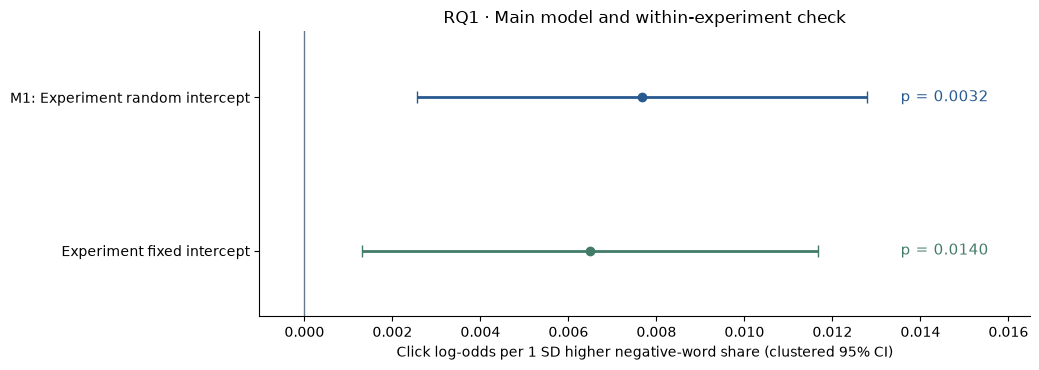

In [16]:
main_term = m1_table.set_index("term").loc["z_neg"]
fixed_term = rq1_within.set_index("term").loc["z_neg"]
estimates = [
    ("M1: Experiment random intercept", main_term.coef, main_term.cluster_low,
     main_term.cluster_high, main_term.p_robust, "#285a90"),
    ("Experiment fixed intercept", fixed_term.coef, fixed_term.ci_low,
     fixed_term.ci_high, fixed_term.p_cluster, "#427b68"),
]

fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.axvline(0, lw=1, color="#68788b", zorder=0)
min_bound = min(0, *(low for _, _, low, _, _, _ in estimates))
max_bound = max(0, *(high for _, _, _, high, _, _ in estimates))
span = max_bound - min_bound
for position, (label, coefficient, low, high, p_value, color) in enumerate(estimates):
    ax.errorbar(coefficient, position, xerr=[[coefficient-low], [high-coefficient]],
                fmt="o", color=color, capsize=4, linewidth=2)
    ax.text(max_bound + span*.06, position, f"p = {p_value:.4f}",
            va="center", color=color, fontsize=11)
ax.set(
    title="RQ1 · Main model and within-experiment check",
    xlabel="Click log-odds per 1 SD higher negative-word share (clustered 95% CI)",
    yticks=[0, 1],
    yticklabels=[row[0] for row in estimates],
    ylim=(1.43, -.43),
    xlim=(min_bound-span*.08, max_bound+span*.29),
)
finish_plot(fig, ax, "08_rq1_within_experiment.png")

## Figure · Predicted CTR with pointwise confidence band

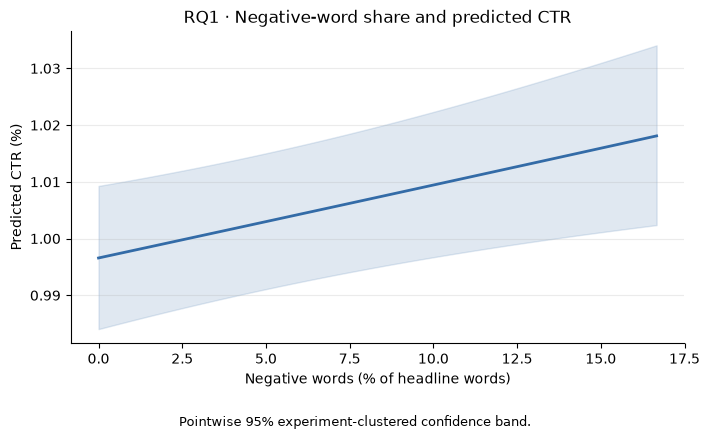

,contrast,estimate,ci_low,ci_high,p
0,0% to 5.93%,0.7603,0.2557,1.2648,0.0031


In [17]:
neg=d.neg_prop_nrc
neg_sd=neg.std(ddof=0)
share=np.linspace(neg.min(),neg.quantile(.95),100)
fig,ax=plt.subplots(figsize=(7.2,4.4))
prediction(ax,m1,names1,share,0,"#336ba7")
ax.set(title="RQ1 · Negative-word share and predicted CTR",
       xlabel="Negative words (% of headline words)",ylabel="Predicted CTR (%)")
ax.grid(axis="y",alpha=.25)
fig.text(.5,.02,"Pointwise 95% experiment-clustered confidence band.",ha="center",fontsize=9)
fig.subplots_adjust(bottom=.17)
finish_plot(fig,ax,"02_rq1_predicted_ctr.png")
m1_change=pd.DataFrame([contrast_row(f"0% to {neg_sd:.2%}",m1,
    prediction_rows(names1,[0,neg_sd]),np.array([-1,1]))])
display(m1_change.round(4))

## Exploratory model · Presence versus positive dose

In [18]:
has_negative=neg.gt(0)
median_positive=neg[has_negative].median()
positive_dose=(neg-median_positive).where(has_negative,0)/.05
controls=Z1.drop(columns="z_neg")
dose_names=["Intercept","has_negative","positive_dose",*controls.columns]
dose_design=np.column_stack([np.ones(len(d)),has_negative,positive_dose,controls])
dose_fit=fit_glmm(y,n,dose_design,g,dose_names)
display(fit_table(dose_fit).round(6))
print(f"Zero share: {(~has_negative).mean():.2%} | Median among positive shares: {median_positive:.2%}")

,term,coef,se,p,se_robust,p_robust,ordinary_low,ordinary_high,cluster_low,cluster_high
0,Intercept,-4.607620,0.006246,0.000000,0.006708,0.000000,-4.619862,-4.595378,-4.620767,-4.594474
1,has_negative,0.033046,0.002120,0.000000,0.005164,0.000000,0.028890,0.037201,0.022925,0.043167
2,positive_dose,-0.009499,0.001432,0.000000,0.003425,0.005544,-0.012306,-0.006692,-0.016212,-0.002787
3,z_pos,-0.010099,0.001081,0.000000,0.002618,0.000115,-0.012219,-0.007980,-0.015231,-0.004968
4,z_fog,-0.002513,0.001075,0.019371,0.002642,0.341603,-0.004619,-0.000407,-0.007692,0.002666
5,z_len,0.035969,0.001130,0.000000,0.002711,0.000000,0.033754,0.038184,0.030655,0.041283
6,z_day,-0.219386,0.005811,0.000000,0.005744,0.000000,-0.230776,-0.207997,-0.230644,-0.208128


Zero share: 48.09% | Median among positive shares: 7.69%


## Figure · Two exploratory click contrasts

,contrast,estimate,ci_low,ci_high,p
0,0% to 7.69%,3.2846,2.2780,4.2912,0.0000
1,7.69% to 12.69%,-0.9551,-1.6288,-0.2814,0.0055


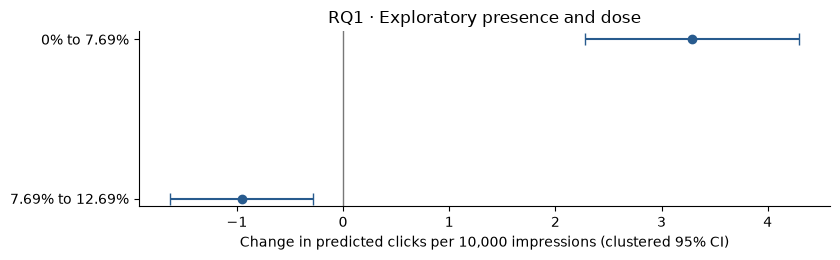

In [19]:
rows=np.zeros((3,len(dose_names)))
rows[:,0]=1
rows[1:,1]=1
rows[2,2]=1
effects=pd.DataFrame([
    contrast_row(f"0% to {median_positive:.2%}",dose_fit,rows[:2],np.array([-1,1])),
    contrast_row(f"{median_positive:.2%} to {median_positive+.05:.2%}",dose_fit,rows[1:],np.array([-1,1])),
])
effects.to_csv(RUN_DIR/"RQ1_presence_dose_contrasts.csv",index=False)
display(effects.round(4))
plot_intervals(effects,"RQ1 · Exploratory presence and dose",
    "Change in predicted clicks per 10,000 impressions (clustered 95% CI)","07_rq1_presence_dose.png")